This continues from assignment1 Part 4(a) and 4(b). 

## -Data Importing and Preparation-

In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


from sklearn.model_selection import train_test_split, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

#Load the seaborn diamonds data set into a Pandas DataFrame
df = sns.load_dataset('diamonds')
#Starting number of columns and rows in the data set
df.shape

(53940, 10)

In [2]:
#Reconstruct the Training and Testing Data sets using ordinal encoded categorical features
#Save the datasets into a variable for later use.
categorical_features = ['cut', 'color', 'clarity']
numerical_features = ['carat', 'depth', 'table', 'x', 'y', 'z']

#3 ranked ordered using ordinal encoding for categorical features
#I want to see them all for all 3 categorical features from the data set
df['cut'].unique()


['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Categories (5, str): ['Ideal', 'Premium', 'Very Good', 'Good', 'Fair']

In [3]:
df['color'].unique()

['E', 'I', 'J', 'H', 'F', 'G', 'D']
Categories (7, str): ['D', 'E', 'F', 'G', 'H', 'I', 'J']

In [4]:
df['clarity'].unique()

['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF']
Categories (8, str): ['IF', 'VVS1', 'VVS2', 'VS1', 'VS2', 'SI1', 'SI2', 'I1']

In [5]:
#To see what is in numerical features
df[numerical_features].head()

,carat,depth,table,x,y,z
0,0.23,61.5,55.0,3.95,3.98,2.43
1,0.21,59.8,61.0,3.89,3.84,2.31
2,0.23,56.9,65.0,4.05,4.07,2.31
3,0.29,62.4,58.0,4.20,4.23,2.63
4,0.31,63.3,58.0,4.34,4.35,2.75


### Need to clean the data once again; remove zero, duplicates and checking bounds

In [6]:
#-ZERO VALUES-
#1.Zero count per row 
zero_count_per_row = (df[['x', 'y', 'z']] == 0).sum(axis=1)

#1a. Verify how many rows have more than 1 zero value in x,y,or z
zero_count_per_row[zero_count_per_row > 1].count()


np.int64(8)

In [7]:
#2.we will remove those rows with more than 1 zero value in x,y,or z
df = df[zero_count_per_row <= 1]

#2a. Verify how many rows were removed from the data set
df.shape
#print("Number of rows removed:", 53940 - df.shape[0])

(53932, 10)

In [8]:
#The remaining 0's in column z will be imputed
#Convert depth to a decimal value by dividing by 100
depth = df['depth'] / 100

#Calculate the average of x and y now
average_x_y = (df['x'] + df['y']) / 2

#Calculate what the value of z should be based on the average of x and y and the depth
z_values = average_x_y * depth

#Now I can replace the 0's in z with the calculated values
df['z'] = np.where(df['z'] == 0, z_values, df['z'])
#REMEMBER: np.where() helps to replace values in a column based on a condition. 
    #In this case, we are checking if the value in the 'z' column is 0, and if it is, we replace it with the calculated value from z_values. 
    #This way I am not replacing/erasing values in all z column rows, only those that are 0.

In [9]:
#VERIFICATION to make sure there are no more 0's in the z column
(df['z'] == 0).sum()

np.int64(0)

In [10]:
df.shape
#I didn't create new columns; 10 columns with price being the target variable.
#That leaves 9 columns for the categorical and numerical features. 3 categorical and 6 numerical features.

(53932, 10)

In [11]:
#-BOUNDS-
#I will check rows to make sure they are within the bounds: 1 <= x <= 11, 1 <= y <= 11, and 1 <= z <= 11
x_bounds_check = df[(df['x'] < 1) | (df['x'] > 11)]
y_bounds_check = df[(df['y'] < 1) | (df['y'] > 11)]
z_bounds_check = df[(df['z'] < 1) | (df['z'] > 11)]
print(x_bounds_check)
print()
print(y_bounds_check)
print()
print(z_bounds_check)

Empty DataFrame
Columns: [carat, cut, color, clarity, depth, table, price, x, y, z]
Index: []

       carat      cut color clarity  depth  table  price     x     y     z
24067   2.00  Premium     H     SI2   58.9   57.0  12210  8.09  58.9  8.06
49189   0.51    Ideal     E     VS1   61.8   55.0   2075  5.15  31.8  5.12

       carat        cut color clarity  depth  table  price     x     y     z
48410   0.51  Very Good     E     VS1   61.8   54.7   1970  5.12  5.15  31.8


In [12]:
#These 3 rows can be removed from the data set since they are out of bounds for x, y, and z.
df = df[(df['x'] >= 1) & (df['x'] <= 11) & (df['y'] >= 1) & (df['y'] <= 11) & (df['z'] >= 1) & (df['z'] <= 11)]
df.shape
#print("Number of rows removed:", 53932 - df.shape[0])

(53929, 10)

In [13]:
#-DUPLICATES-
#This is the last step in cleaning the data set. I will check for duplicates and remove them if they exist.
duplicates = df.duplicated()
print("Number of duplicate rows:", duplicates.sum())

Number of duplicate rows: 145


In [14]:
#Removing duplicates rows, 145 rows
df = df.drop_duplicates()
df.shape
#print("Number of rows removed:", 53929 - df.shape[0])

(53784, 10)

### Split data into training and test sets since data is now clean

In [15]:
#Splitting data into training and testing sets
#Like in assignment 1, the ratio of training to testing data will be 80% to 20%.

X = df.drop(columns='price')
y = df['price']  

X_train, X_test, y_train, y_test = train_test_split(
   X, y,
   test_size=0.2,  # 20% for testing
   random_state=432  # For reproducibility
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((43027, 9), (10757, 9), (43027,), (10757,))

### Data is clean, split into 2 sets , and now the categorical features need to be ordinal encoded  (working with categorical features only)

In [16]:
#Need 3 ranked ordered lists from the categorical features in the data set. I will use ordinal encoding to do this.
#REMEMBER: ORDER IS FROM BEST TO WORST FOR CUT, COLOR, AND CLARITY.
cut_labels = ['Ideal', 'Premium', 'Very Good', 'Good', 'Fair']
color_labels = ['D', 'E', 'F', 'G', 'H', 'I', 'J']
clarity_labels = ['IF', 'VVS1', 'VVS2', 'VS1', 'VS2', 'SI1', 'SI2', 'I1']

#Now we do the OrdinalEncoder for the categorical features in the data set. I will use the lists above to do this.
ordinal_encoder = OrdinalEncoder(categories=[cut_labels, color_labels, clarity_labels])

# Fit the encoder to the categorical features in the training set: Transforming Categorical Features
standard_scaler = StandardScaler()
column_transformer_ordinal = ColumnTransformer(
    transformers=[
        ('ordinal', ordinal_encoder, categorical_features),
        ('scaler', standard_scaler, numerical_features)
    ]
)

X_train_ordencoded = column_transformer_ordinal.fit_transform(X_train)
X_test_ordencoded = column_transformer_ordinal.transform(X_test)

In [17]:
X_train_ordencoded.shape, X_test_ordencoded.shape
print("Training set with 20% data has", X_train_ordencoded.shape[0], "rows and", X_train_ordencoded.shape[1], "columns.")
print("Testing set with 20% data has", X_test_ordencoded.shape[0], "rows and", X_test_ordencoded.shape[1], "columns."    )

Training set with 20% data has 43027 rows and 9 columns.
Testing set with 20% data has 10757 rows and 9 columns.


### Training and Testing Data sets with OneHotEncoder for the categorical features. Save the dataset using a properly named variable.

In [18]:
#Creating OneHotEncoder for the categorical features in the data set. I will use the lists above 
onehot_encoder = OneHotEncoder(drop='first', sparse_output=False)
column_transformer_ohc = ColumnTransformer(
    transformers=[
        ('onehot', onehot_encoder, categorical_features),
        ('scale', standard_scaler, numerical_features)
    ],
)

#Now I can fit the OneHotEncoder to the categorical features in training and testing data sets. 
X_train_ohc = column_transformer_ohc.fit_transform(X_train)
X_test_ohc = column_transformer_ohc.transform(X_test)

In [19]:
X_train_ohc.shape, X_test_ohc.shape

((43027, 23), (10757, 23))

#### -Models with Default Hyperparameter Settings- Part 2

Create instances of following 4 algorithms:

In [20]:
#LinearRegresssion Instance
from sklearn.linear_model import Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor

linear_model = LinearRegression(fit_intercept=True)

linear_model.get_params()
#In lecture we were told about fit_intercept which helps calculate the y-intercept of the regression line. 

{'copy_X': True,
 'fit_intercept': True,
 'n_jobs': None,
 'positive': False,
 'tol': 1e-06}

In [21]:
#Lasso Instance (inc max_iter to avoid convergence warnings)
lasso_model = Lasso(max_iter=10000)

lasso_model.get_params()

{'alpha': 1.0,
 'copy_X': True,
 'fit_intercept': True,
 'max_iter': 10000,
 'positive': False,
 'precompute': False,
 'random_state': None,
 'selection': 'cyclic',
 'tol': 0.0001,
 'warm_start': False}

In [22]:
#Ridge Instance (inc max_iter to avoid convergence warnings)
ridge_model = Ridge(max_iter=10000)

ridge_model.get_params()

{'alpha': 1.0,
 'copy_X': True,
 'fit_intercept': True,
 'max_iter': 10000,
 'positive': False,
 'random_state': None,
 'solver': 'auto',
 'tol': 0.0001}

In [23]:
#DecisionTreeRegressor Instance (set the random_state parameter)
tree_model = DecisionTreeRegressor(random_state=432)

tree_model.get_params()
#If its a tree then max_depth': None must mean it can grow as deep as it wants. 

{'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 432,
 'splitter': 'best'}

#### Now with the Training Data that includes ordinal enconded categorical features and the 4 instances created above, do  the following: 

In [24]:
#The cross validation RMSE scores for each of the 5 folds
#https://www.kaggle.com/code/satishgunjal/tutorial-k-fold-cross-validation
#In the end every block of data would have been used for testing and training. 
#https://youtu.be/fSytzGwwBVw?si=8VHjK6sg-VtaPQcI


cross_val_results = cross_validate(
    estimator=linear_model,  # Use the existing LinearRegression instance
    X=X_train_ordencoded,
    y=y_train,
    cv=5,
    scoring=['neg_root_mean_squared_error', 'neg_mean_absolute_error'],
)

print("Cross validation dictionary features:", cross_val_results.keys() )
print()
print("Cross validation RMSE scores for each fold:", -cross_val_results['test_neg_root_mean_squared_error'])

Cross validation dictionary features: dict_keys(['fit_time', 'score_time', 'test_neg_root_mean_squared_error', 'test_neg_mean_absolute_error'])

Cross validation RMSE scores for each fold: [1214.42774249 1169.56694013 1190.10643762 1237.66558793 1217.60269943]


In [25]:
#The avg RMSE over the 5 folds, Standard Deviation of the RMSE over the 5 folds, cross validation MAE scores for each of the 5 folds, and standar deviation of MAE for each of the 5 folds

avg_rmse = np.mean(-cross_val_results['test_neg_root_mean_squared_error'])
std_rmse = np.std(-cross_val_results['test_neg_root_mean_squared_error'])
avg_mae = np.mean(-cross_val_results['test_neg_mean_absolute_error'])
std_mae = np.std(-cross_val_results['test_neg_mean_absolute_error'])

print("LinearRegression Model Metrics:")
print("RMSE Values:", -cross_val_results['test_neg_root_mean_squared_error'])
print("Mean RMSE Values:", avg_rmse)
print("Sigma RMSE Values:", std_rmse)
#MAE Values has 5 scores for each of the 5 folds
print("MAE Values:", -cross_val_results['test_neg_mean_absolute_error'])
print("Mean MAE Values:", avg_mae)
print("Sigma MAE Values:", std_mae)

LinearRegression Model Metrics:
RMSE Values: [1214.42774249 1169.56694013 1190.10643762 1237.66558793 1217.60269943]
Mean RMSE Values: 1205.8738815173922
Sigma RMSE Values: 23.61462506093032
MAE Values: [805.00321976 786.73136968 793.73853275 805.02544315 802.9624989 ]
Mean MAE Values: 798.6922128471842
Sigma MAE Values: 7.290743075636547


In [26]:
#Cross validation for the Lasso model
cross_val_results_lasso = cross_validate(
    estimator=lasso_model,
    X=X_train_ordencoded,
    y=y_train,
    cv=5,
    scoring=['neg_root_mean_squared_error', 'neg_mean_absolute_error'],
)

In [27]:
#To see the results of the 5 folds for the Lasso model, I will print the RMSE and MAE values for each fold, as well as their means and standard deviations.
avg_rmse_lasso = np.mean(-cross_val_results_lasso['test_neg_root_mean_squared_error'])
std_rmse_lasso = np.std(-cross_val_results_lasso['test_neg_root_mean_squared_error'])
avg_mae_lasso = np.mean(-cross_val_results_lasso['test_neg_mean_absolute_error'])
std_mae_lasso = np.std(-cross_val_results_lasso['test_neg_mean_absolute_error'])

print("Lasso Model Metrics:")
print("RMSE Values:", -cross_val_results_lasso['test_neg_root_mean_squared_error'])
print("RMSE Mean:", avg_rmse_lasso)
print("Sigma RMSE:", std_rmse_lasso)
print("MAE Values:", -cross_val_results_lasso['test_neg_mean_absolute_error'])
print("MAE Mean:", avg_mae_lasso)
print("Sigma MAE:", std_mae_lasso)

Lasso Model Metrics:
RMSE Values: [1214.30569345 1171.5930323  1190.39339117 1238.41644767 1218.39416795]
RMSE Mean: 1206.6205465097316
Sigma RMSE: 23.233193056247007
MAE Values: [804.96324149 787.13482121 794.37490806 805.50963153 802.53590318]
MAE Mean: 798.9037010947208
Sigma MAE: 7.1072602146760655


In [28]:
#Cross validation for the Ridge model
cross_val_results_ridge = cross_validate(
    estimator=ridge_model,
    X=X_train_ordencoded,
    y=y_train,
    cv=5,
    scoring=['neg_root_mean_squared_error', 'neg_mean_absolute_error'],
)

#To see the results for the Ridge model, I will print the RMSE and MAE values for each fold, as well as their means and standard deviations.
avg_rmse_ridge = np.mean(-cross_val_results_ridge['test_neg_root_mean_squared_error'])
std_rmse_ridge = np.std(-cross_val_results_ridge['test_neg_root_mean_squared_error'])
avg_mae_ridge = np.mean(-cross_val_results_ridge['test_neg_mean_absolute_error'])
std_mae_ridge = np.std(-cross_val_results_ridge['test_neg_mean_absolute_error'])

print("Ridge Model Metrics:")
print("RMSE Values:", -cross_val_results_ridge['test_neg_root_mean_squared_error'])
print("RMSE Mean:", avg_rmse_ridge)
print("Sigma RMSE:", std_rmse_ridge)
print("MAE Values:", -cross_val_results_ridge['test_neg_mean_absolute_error'])
print("MAE Mean:", avg_mae_ridge)
print("Sigma MAE:", std_mae_ridge)

Ridge Model Metrics:
RMSE Values: [1214.34626624 1169.67293799 1190.05651785 1237.63763367 1217.56581898]
RMSE Mean: 1205.8558349464959
Sigma RMSE: 23.571653878957626
MAE Values: [805.03069386 786.79226195 793.77199461 805.07211083 802.92916557]
MAE Mean: 798.719245363539
Sigma MAE: 7.2752310395838


In [29]:
#Cross validation for the Tree model
cross_val_results_tree = cross_validate(
    estimator=tree_model,
    X=X_train_ordencoded,
    y=y_train,
    cv=5,
    scoring=['neg_root_mean_squared_error', 'neg_mean_absolute_error'],
)

#To view the results for the DecisionTreeRegressor model, I will print the RMSE and MAE values for each fold, as well as their means and standard deviations.
avg_rmse_tree = np.mean(-cross_val_results_tree['test_neg_root_mean_squared_error'])
std_rmse_tree = np.std(-cross_val_results_tree['test_neg_root_mean_squared_error'])
avg_mae_tree = np.mean(-cross_val_results_tree['test_neg_mean_absolute_error'])
std_mae_tree = np.std(-cross_val_results_tree['test_neg_mean_absolute_error'])

print("Decision Tree Model Metrics:")
print("RMSE Values:", -cross_val_results_tree['test_neg_root_mean_squared_error'])
print("RMSE Mean:", avg_rmse_tree)
print("Sigma RMSE:", std_rmse_tree)
print("MAE Values:", -cross_val_results_tree['test_neg_mean_absolute_error'])
print("MAE Mean:", avg_mae_tree)
print("Sigma MAE:", std_mae_tree)

Decision Tree Model Metrics:
RMSE Values: [754.47842465 716.74783223 708.63799264 748.3405853  760.29275412]
RMSE Mean: 737.699517788755
Sigma RMSE: 20.922541589171306
MAE Values: [365.52062515 354.91616314 354.98239396 362.55444509 367.42922719]
MAE Mean: 361.0805709055598
Sigma MAE: 5.241746056360521


#### With the Training Data that includes OneHotEncoded categorical features and the 4 instances created above, do the following: 

In [30]:
#Now its cross validation for the OneHotEncoder data set. I will use the same models as before, but this time I will use the OneHotEncoded data set instead of the OrdinalEncoded data set.
cross_val_results_ohe = cross_validate(
    estimator=linear_model,
    X=X_train_ohc,
    y=y_train,
    cv=5,
    scoring=['neg_root_mean_squared_error', 'neg_mean_absolute_error'],
)

#To view the results for the LinearRegression model using the OneHotEncoded data set, I will print the RMSE and MAE values for each fold, as well as their means and standard deviations.
avg_rmse_ohe = np.mean(-cross_val_results_ohe['test_neg_root_mean_squared_error'])
std_rmse_ohe = np.std(-cross_val_results_ohe['test_neg_root_mean_squared_error'])
avg_mae_ohe = np.mean(-cross_val_results_ohe['test_neg_mean_absolute_error'])
std_mae_ohe = np.std(-cross_val_results_ohe['test_neg_mean_absolute_error'])

print("Linear Regression Model Metrics (OneHotEncoded):")
print("RMSE Values:", -cross_val_results_ohe['test_neg_root_mean_squared_error'])
print("RMSE Mean:", avg_rmse_ohe)
print("Sigma RMSE:", std_rmse_ohe)
print("MAE Values:", -cross_val_results_ohe['test_neg_mean_absolute_error'])    
print("MAE Mean:", avg_mae_ohe)
print("Sigma MAE:", std_mae_ohe)

Linear Regression Model Metrics (OneHotEncoded):
RMSE Values: [1129.62407024 1086.93223764 1117.13776283 1147.6478582  1129.17378158]
RMSE Mean: 1122.1031420985546
Sigma RMSE: 20.103424260058176
MAE Values: [732.33829785 721.45947455 735.38792455 741.68249481 734.28422992]
MAE Mean: 733.0304843369064
Sigma MAE: 6.578055595091391


In [31]:
#Cross validation for the Lasso model
cross_val_results_ohe_lasso = cross_validate(
    estimator=lasso_model,
    X=X_train_ohc,
    y=y_train,
    cv=5,
    scoring=['neg_root_mean_squared_error', 'neg_mean_absolute_error'],
)

#To view the results for the Lasso model using the OneHotEncoded data set, I will print the RMSE and MAE values for each fold, as well as their means and standard deviations.
avg_rmse_ohe_lasso = np.mean(-cross_val_results_ohe_lasso['test_neg_root_mean_squared_error'])
std_rmse_ohe_lasso = np.std(-cross_val_results_ohe_lasso['test_neg_root_mean_squared_error'])
avg_mae_ohe_lasso = np.mean(-cross_val_results_ohe_lasso['test_neg_mean_absolute_error'])
std_mae_ohe_lasso = np.std(-cross_val_results_ohe_lasso['test_neg_mean_absolute_error'])

print("Lasso Model Metrics (OneHotEncoded):")
print("RMSE Values:", -cross_val_results_ohe_lasso['test_neg_root_mean_squared_error'])
print("RMSE Mean:", avg_rmse_ohe_lasso)
print("Sigma RMSE:", std_rmse_ohe_lasso)
print("MAE Values:", -cross_val_results_ohe_lasso['test_neg_mean_absolute_error'])
print("MAE Mean:", avg_mae_ohe_lasso)
print("Sigma MAE:", std_mae_ohe_lasso)

Lasso Model Metrics (OneHotEncoded):
RMSE Values: [1130.94458439 1089.62673743 1116.93059751 1152.12977184 1134.1194356 ]
RMSE Mean: 1124.7502253537273
Sigma RMSE: 20.83553567458726
MAE Values: [727.92476732 717.36525716 730.33462367 735.96095851 730.36318572]
MAE Mean: 728.3897584743856
Sigma MAE: 6.111560059874435


In [32]:
#Cross validation for the Ridge model
cross_val_results_ohe_ridge = cross_validate(
    estimator=ridge_model,
    X=X_train_ohc,
    y=y_train,
    cv=5,
    scoring=['neg_root_mean_squared_error', 'neg_mean_absolute_error'],
)

#To view the results for the Ridge model using the OneHotEncoded data set, I will print the RMSE and MAE values for each fold, as well as their means and standard deviations.
avg_rmse_ohe_ridge = np.mean(-cross_val_results_ohe_ridge['test_neg_root_mean_squared_error'])
std_rmse_ohe_ridge = np.std(-cross_val_results_ohe_ridge['test_neg_root_mean_squared_error'])
avg_mae_ohe_ridge = np.mean(-cross_val_results_ohe_ridge['test_neg_mean_absolute_error'])
std_mae_ohe_ridge = np.std(-cross_val_results_ohe_ridge['test_neg_mean_absolute_error'])    

print("Ridge Model Metrics (OneHotEncoded):")
print("RMSE Values:", -cross_val_results_ohe_ridge['test_neg_root_mean_squared_error'])
print("RMSE Mean:", avg_rmse_ohe_ridge)
print("Sigma RMSE:", std_rmse_ohe_ridge)
print("MAE Values:", -cross_val_results_ohe_ridge['test_neg_mean_absolute_error'])
print("MAE Mean:", avg_mae_ohe_ridge)
print("Sigma MAE:", std_mae_ohe_ridge)

Ridge Model Metrics (OneHotEncoded):
RMSE Values: [1129.49611045 1086.88366709 1116.80666254 1147.91556177 1129.48559512]
RMSE Mean: 1122.1175193926983
Sigma RMSE: 20.218311923034427
MAE Values: [731.73341872 720.96339993 734.7763107  741.02772905 733.84583547]
MAE Mean: 732.4693387743691
Sigma MAE: 6.532857163689832


In [33]:
#Cross validation for the Tree model(DecisionTreeRegressor) using the OneHotEncoded data set
cross_val_results_ohe_tree = cross_validate(
    estimator=tree_model,
    X=X_train_ohc,
    y=y_train,
    cv=5,
    scoring=['neg_root_mean_squared_error', 'neg_mean_absolute_error'],
)

#To view the results for the Tree model using the OneHotEncoded data set, I will print the RMSE and MAE values for each fold, as well as their means and standard deviations.
avg_rmse_ohe_tree = np.mean(-cross_val_results_ohe_tree['test_neg_root_mean_squared_error'])
std_rmse_ohe_tree = np.std(-cross_val_results_ohe_tree['test_neg_root_mean_squared_error'])
avg_mae_ohe_tree = np.mean(-cross_val_results_ohe_tree['test_neg_mean_absolute_error'])
std_mae_ohe_tree = np.std(-cross_val_results_ohe_tree['test_neg_mean_absolute_error'])

print("Tree Model Metrics (OneHotEncoded):")
print("RMSE Values:", -cross_val_results_ohe_tree['test_neg_root_mean_squared_error'])
print("RMSE Mean:", avg_rmse_ohe_tree)
print("Sigma RMSE:", std_rmse_ohe_tree)
print("MAE Values:", -cross_val_results_ohe_tree['test_neg_mean_absolute_error'])
print("MAE Mean:", avg_mae_ohe_tree)
print("Sigma MAE:", std_mae_ohe_tree)

Tree Model Metrics (OneHotEncoded):
RMSE Values: [924.3182976  836.54091042 864.80427211 876.31496317 882.36063771]
RMSE Mean: 876.8678161995942
Sigma RMSE: 28.473894518948818
MAE Values: [408.17075296 383.82674878 391.96873911 397.45316676 397.03097037]
MAE Mean: 395.6900755955435
Sigma MAE: 7.940537327067775


#### Discussion

In [34]:
#I want to see the price of diamonds from the training data set. 
#By seeing the prices, I will be able to see the mean, minimum, and maximum prices of diamonds in the training data set. 
#This range will help me compare them to the table below that shows the RMSE and MAE values for the 4 models using both OrdinalEncoded and OneHotEncoded data sets.
print(f"Mean price of diamonds in the dataset:", f"{y_train.mean():.3f}")
mean_price = y_train.mean()
print(f"Mean price: ${mean_price:.2f}")

print(f"Minimum price of diamonds in the dataset:", f"{y_train.min():.3f}")
print(f"Maximum price of diamonds in the dataset:", f"{y_train.max():.3f}")


Mean price of diamonds in the dataset: 3939.573
Mean price: $3939.57
Minimum price of diamonds in the dataset: 326.000
Maximum price of diamonds in the dataset: 18823.000


In [35]:
#A table or something like it to see all results for the 4 models using both OrdinalEncoded and OneHotEncoded data sets.
comparison_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Lasso', 'Ridge', 'Decision Tree'],
    'Ord_RMSE_Mean': [f"{avg_rmse:.3f}", f"{avg_rmse_lasso:.3f}", f"{avg_rmse_ridge:.3f}", f"{avg_rmse_tree:.3f}"],
    'Ord_RMSE_Std': [f"{std_rmse:.3f}", f"{std_rmse_lasso:.3f}", f"{std_rmse_ridge:.3f}", f"{std_rmse_tree:.3f}"],
    'Ord_MAE_Mean': [f"{avg_mae:.3f}", f"{avg_mae_lasso:.3f}", f"{avg_mae_ridge:.3f}", f"{avg_mae_tree:.3f}"],
    'Ord_MAE_Std': [f"{std_mae:.3f}", f"{std_mae_lasso:.3f}", f"{std_mae_ridge:.3f}", f"{std_mae_tree:.3f}"],
    'OHE_RMSE_Mean': [f"{avg_rmse_ohe:.3f}", f"{avg_rmse_ohe_lasso:.3f}", f"{avg_rmse_ohe_ridge:.3f}", f"{avg_rmse_ohe_tree:.3f}"],
    'OHE_RMSE_Std': [f"{std_rmse_ohe:.3f}", f"{std_rmse_ohe_lasso:.3f}", f"{std_rmse_ohe_ridge:.3f}", f"{std_rmse_ohe_tree:.3f}"],
    'OHE_MAE_Mean': [f"{avg_mae_ohe:.3f}", f"{avg_mae_ohe_lasso:.3f}", f"{avg_mae_ohe_ridge:.3f}", f"{avg_mae_ohe_tree:.3f}"],
    'OHE_MAE_Std': [f"{std_mae_ohe:.3f}", f"{std_mae_ohe_lasso:.3f}", f"{std_mae_ohe_ridge:.3f}", f"{std_mae_ohe_tree:.3f}"]
})
comparison_df

,Model,Ord_RMSE_Mean,Ord_RMSE_Std,Ord_MAE_Mean,Ord_MAE_Std,OHE_RMSE_Mean,OHE_RMSE_Std,OHE_MAE_Mean,OHE_MAE_Std
0,Linear Regression,1205.874,23.615,798.692,7.291,1122.103,20.103,733.030,6.578
1,Lasso,1206.621,23.233,798.904,7.107,1124.750,20.836,728.390,6.112
2,Ridge,1205.856,23.572,798.719,7.275,1122.118,20.218,732.469,6.533
3,Decision Tree,737.700,20.923,361.081,5.242,876.868,28.474,395.690,7.941


The first three Linear Regression , Lasso, Ridge have values all around 1205 for ordinal and 1122 for OHE. They are not the same, if you subtract them, their difference is 83. 

The Decision Tree did much better than all three linear models, RMSE of ~738 vs ~1205 for ordinal. This tells me the data doesn't follow a simple straight line pattern, and the Decision Tree was better at finding  more relationships between diamond features and price. So I wonder if these lower values are better or not when finding the difference between these values and the mean price,but that difference wouldn't be big if compared to the minimum price of a diamond. I am unsure why but I would say I would want to know more. In class we learned that we are trying to fit results, predictions in a line or the s shape model but that isn't always the best as decision tree has proven. 

### -Turning Model Hyperparameters- Part 3

#### Grid Search will try every vallue I give it, almost like brute force trying every combination. I will need a parameter grid that's a dictionary telling me what values to try for the "alpha" which so far has been at a default of 1.0.  

In [36]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import cross_val_score, cross_validate, GridSearchCV, KFold

#From notes:
#lasso_reg_grid = [
##    {'fit_intercept':[True, False], 
## 'positive':[True, False],
##     'alpha':np.logspace(np.log10(0.001), np.log10(10), 100)
#}
#]
#lasso_grid_search = GridSearchCV(estimator= lasso_regressor, 
##                                 param_grid= lasso_reg_grid, 
##                                 cv= 5, 
##                                 verbose= 1, 
##                                 scoring= 'neg_root_mean_squared_error',
##                                 refit= True
#                                )

#lasso_grid_search.fit(X= X_train, y= y_train)


#Employ GridSearch over values of alpha and using the Training Data with ordinal enconded of categorical features
#Show the best alpha value and best score from the Ridge model
ridge_grid_search_ordencoded = GridSearchCV(
    estimator=ridge_model,
    param_grid={'alpha': np.logspace(np.log10(0.01), np.log10(5), 100)},
    cv=5,
    verbose=1,
    scoring='neg_root_mean_squared_error',
    refit=True
)
#REMEMBER TO USE THE VARIABLE NAMING USE PREVIOUSLY FOR THE "RIDGE INSTANCE"
#CONSIDER ONLY RMSE METRICS
ridge_grid_search_ordencoded.fit(X=X_train_ordencoded, y=y_train)
print("Best alpha:", ridge_grid_search_ordencoded.best_params_['alpha'])
print("Best RMSE score:", -ridge_grid_search_ordencoded.best_score_)
print("To compare previous RMSE scores: ", avg_rmse_ridge)


Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best alpha: 2.841901981608688
Best RMSE score: 1205.8440649834024
To compare previous RMSE scores:  1205.8558349464959


#### Identify the optimal regularization strength for the Ridge regressor by employing a Grid Search: Create a GridSearchCV instance,Use the Lasso instance from Part 2(a), ONLY consider RMSE, alpha= [0.01, 5], Use Training Data with ordinal encoding, Show optimal alpha and best score

https://www.w3schools.com/python/python_ml_grid_search.asp
https://www.digitalocean.com/community/tutorials/grid-searching-using-python

We learned in class that a hyperparameter is a setting that is chosen before using it on the training model. Grid search is a method use to find the best combinastion of hyperparameters for a model by trying them all at once within a range. 

In [37]:
#Create a GridSearchCV isntance and save it
ridge_grid_search_ohc = GridSearchCV(
    estimator=ridge_model,
    param_grid={'alpha': np.logspace(np.log10(0.01), np.log10(5), 100)},
    cv=5,
    verbose=1,
    scoring='neg_root_mean_squared_error',
    refit=True
)
#Use ridge_grid_search_ohc instance  to calculate best alpha and best score from grid search for the Ridge model using the OneHotEncoded data set.
ridge_grid_search_ohc.fit(X=X_train_ohc, y=y_train)
print("Best alpha:", ridge_grid_search_ohc.best_params_['alpha'])
print("Best RMSE score:", -ridge_grid_search_ohc.best_score_)
print("To compare previous RMSE scores: ", avg_rmse_ohe)


Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best alpha: 0.24568491238055393
Best RMSE score: 1122.1012732318677
To compare previous RMSE scores:  1122.1031420985546


#### Use the lasso method to create a GridSearchCV instance, Use the Lasso instance from the previous step, ONLY consider RMSE, alpha=[0.01,5], Use Training Data with ordinal encoding, Show optimal alpha and best score. 

In [48]:
#Create a GridSearchCV instance and save it -Lasso model
#After contacting the professor, I was advised to reduce my alpha candidates from 100 to 20. 
lasso_grid_search_ordencoded = GridSearchCV(
    estimator=lasso_model,
    param_grid={'alpha': np.logspace(np.log10(0.01), np.log10(5), 20)},
    cv=5,
    verbose=1,
    scoring='neg_root_mean_squared_error',
    refit=True
)   

# Use lasso_grid_search_ordencoded instance to calculate best alpha and best score from lasso model using the OrdinalEncoded data set.
lasso_grid_search_ordencoded.fit(X=X_train_ordencoded, y=y_train)
print("Best alpha:", lasso_grid_search_ordencoded.best_params_['alpha'])
print("Best RMSE score:", -lasso_grid_search_ordencoded.best_score_)
print("To compare previous RMSE scores: ", avg_rmse_lasso)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best alpha: 0.13690156816728805
Best RMSE score: 1205.861560424221
To compare previous RMSE scores:  1206.6205465097316


In [52]:
#Create a GridSearchCV instance and save it -Lasso model OHE
#After contacting the professor, I was advised to reduce my alpha candidates from 100 to 20.
lasso_grid_search_ohc = GridSearchCV(
    estimator=lasso_model,
    param_grid={'alpha': np.logspace(np.log10(0.01), np.log10(5), 20)},
    cv=5,
    verbose=1,
    scoring='neg_root_mean_squared_error',
    refit=True
)
lasso_grid_search_ohc.fit(X=X_train_ohc, y=y_train)
print("Best alpha:", lasso_grid_search_ohc.best_params_['alpha'])
print("Best RMSE score:", -lasso_grid_search_ohc.best_score_)
print("To compare previous RMSE scores:", avg_rmse_ohe_lasso)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best alpha: 0.026677993265203287
Best RMSE score: 1122.102323316189
To compare previous RMSE scores: 1124.7502253537273


#### (Part3e) Decision Tree, find the best depth using Ordinal Enconded Data. Using 2 parameters to search independently and not together: max_depth and min_samples_leaf

Train a default Decision Tree on full ordinal enconded training data to find its natural maximum depth so we can have a "upper limit" for our "search". Use that "max depth" as the UpperBound for both max_depth and min_sample_leaf. Run 2 seperate Grid Seaches. Show "optimal value and best RMSE score for both. 

In [49]:
#REMEMBER YOU ARE USING X_train_ordencoded not the tree_model_ordencoded
#THIS TREE HELPS FIND NATURAL DEPTH OF THE TREE MODEL USING THE ORDINAL ENCODED DATA SET, NOT FOR MAX_DEPTH FOR THE GRIDSEARCHCV
tree_model_natural_depth = DecisionTreeRegressor(random_state=432).fit(X_train_ordencoded, y_train)
print(f"Max depth of the Decision Tree model using OrdinalEncoded data set: {tree_model_natural_depth.get_depth()}")
max_depth_limit = int(tree_model_natural_depth.get_depth() * 1.1) + 1  # Adding 10% to the max depth
print(f"Upper Bound for max_depth: {max_depth_limit}")

#using the max_depth_limit as my upperbound for my search range
np.arange(start=1, stop=max_depth_limit + 1, step=1)

Max depth of the Decision Tree model using OrdinalEncoded data set: 36
Upper Bound for max_depth: 40


array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40])

Ordinal Enconded using Training Data

In [50]:
#GridSearchCV instance for both ordinal enconded data sets 


tree_max_depth_grid_search_ordencoded = GridSearchCV(
    estimator=tree_model,
    param_grid={'max_depth': np.arange(start=1, stop=max_depth_limit + 1, step=1)},
    cv=5,
    verbose=1,
    scoring='neg_root_mean_squared_error',
    refit=True
)

tree_max_depth_grid_search_ordencoded.fit(X=X_train_ordencoded, y=y_train)
print("Best max_depth:", tree_max_depth_grid_search_ordencoded.best_params_['max_depth'])
print("Best RMSE score:", -tree_max_depth_grid_search_ordencoded.best_score_)
#to compare previous RMSE scores: ", avg_rmse_tree
print("To compare previous Tree RMSE scores: ", avg_rmse_tree)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best max_depth: 11
Best RMSE score: 631.8209638112929
To compare previous Tree RMSE scores:  737.699517788755


In [41]:
min_sample_leaf_grid_search_ordencoded = GridSearchCV(
    estimator=tree_model,
    param_grid={'min_samples_leaf': np.arange(start=1, stop=max_depth_limit + 1, step=1)},
    cv=5,
    verbose=1,
    scoring='neg_root_mean_squared_error',
    refit=True
)

min_sample_leaf_grid_search_ordencoded.fit(X=X_train_ordencoded, y=y_train)
print("Best min_samples_leaf:", min_sample_leaf_grid_search_ordencoded.best_params_['min_samples_leaf'])
print("Best RMSE score:", -min_sample_leaf_grid_search_ordencoded.best_score_)  
print("To compare previous Tree RMSE scores: ", avg_rmse_tree)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best min_samples_leaf: 10
Best RMSE score: 620.6234805640516
To compare previous Tree RMSE scores:  737.699517788755


In [51]:
#Let make a table with both of these scores for the DecisionTreeRegressor model using the OrdinalEncoded data set. 
#Results for tree_model_natural_depth, max_depth, min_samples_leaf, and the RMSE scores for each of these parameters.
df_tree_results = pd.DataFrame({
    'Parameter': ['Natural Depth', 'Max Depth', 'Min Samples Leaf'],
    'Value': [tree_model_natural_depth.get_depth(), 
              tree_max_depth_grid_search_ordencoded.best_params_['max_depth'], 
              min_sample_leaf_grid_search_ordencoded.best_params_['min_samples_leaf']],
    
    'RMSE': [avg_rmse_tree, 
             -tree_max_depth_grid_search_ordencoded.best_score_, 
             -min_sample_leaf_grid_search_ordencoded.best_score_]
})

df_tree_results #to see the results

,Parameter,Value,RMSE
0,Natural Depth,36,737.699518
1,Max Depth,11,631.820964
2,Min Samples Leaf,10,620.623481


OHE using Training Data 

In [43]:
#OHE natural depth
from sklearn import tree

tree_model_natural_depth_ohe = DecisionTreeRegressor(random_state=432).fit(X_train_ohc, y_train)
print(f"Max depth using OneHotEncoded data set: {tree_model_natural_depth_ohe.get_depth()}")

#Upper Bound for max_depth using OneHotEncoded data set
#This upper bound will be used for the max_depth parameter in the GridSearchCV 
#Best way to round up was to add 10% to the max depth and then add 1 to the result.
max_depth_limit_ohe = int(tree_model_natural_depth_ohe.get_depth() * 1.1) + 1  # Adding 10% to the max depth
print(f"Upper Bound for OneHotEncoded max depth search : {max_depth_limit_ohe}")

Max depth using OneHotEncoded data set: 37
Upper Bound for OneHotEncoded max depth search : 41


In [44]:
#GridSearchCV for 2 sets of OHE data sets

#max_depth parameter
#max_depth is the maximum depth of the tree, if it were drawn.
GridSearchCV_max_depth_ohe = GridSearchCV(
    estimator=tree_model,
    param_grid={'max_depth': np.arange(start=1, stop=max_depth_limit_ohe + 1, step=1)},
    cv=5,
    verbose=1,
    scoring='neg_root_mean_squared_error',
    refit=True
)   

#fit to the training data set
GridSearchCV_max_depth_ohe.fit(X=X_train_ohc, y=y_train)
print("Best max_depth for OneHotEncoded data set:", GridSearchCV_max_depth_ohe.best_params_['max_depth'])
print("Best RMSE score for OneHotEncoded data set:", -GridSearchCV_max_depth_ohe.best_score_)
print("To compare previous Tree RMSE scores: ", avg_rmse_ohe_tree)



Fitting 5 folds for each of 41 candidates, totalling 205 fits
Best max_depth for OneHotEncoded data set: 15
Best RMSE score for OneHotEncoded data set: 833.662037470263
To compare previous Tree RMSE scores:  876.8678161995942


In [45]:
#min_samples_leaf parameter
#min_samples_leaf controls the minimum number of data points required in a leaf node
#Plan to ue the same range as the max_depth parameter for the min_samples_leaf parameter in the GridSearchCV 
GridSearchCV_min_samples_leaf_ohe = GridSearchCV(
    estimator=tree_model,
    param_grid={'min_samples_leaf': np.arange(start=1, stop=max_depth_limit_ohe + 1, step=1)},
    cv=5,
    verbose=1,
    scoring='neg_root_mean_squared_error',
    refit=True
)

#fit to the training data set
GridSearchCV_min_samples_leaf_ohe.fit(X=X_train_ohc, y=y_train)
print("Best min_samples_leaf for OneHotEncoded data set:", GridSearchCV_min_samples_leaf_ohe.best_params_['min_samples_leaf'])
print("Best RMSE score for OneHotEncoded data set:", -GridSearchCV_min_samples_leaf_ohe.best_score_)
print("To compare previous Tree RMSE scores: ", avg_rmse_ohe_tree)

Fitting 5 folds for each of 41 candidates, totalling 205 fits
Best min_samples_leaf for OneHotEncoded data set: 7
Best RMSE score for OneHotEncoded data set: 788.8476576541736
To compare previous Tree RMSE scores:  876.8678161995942


In [46]:
#combine both results into a table using dataframe
df_tree_results_ohe = pd.DataFrame({
    'Parameter': ['Natural Depth', 'Max Depth', 'Min Samples Leaf'],
    'Value': [tree_model_natural_depth_ohe.get_depth(), 
              GridSearchCV_max_depth_ohe.best_params_['max_depth'], 
              GridSearchCV_min_samples_leaf_ohe.best_params_['min_samples_leaf']],
    'RMSE': [avg_rmse_ohe_tree, 
             -GridSearchCV_max_depth_ohe.best_score_, 
             -GridSearchCV_min_samples_leaf_ohe.best_score_]
})
df_tree_results_ohe #to see the results

,Parameter,Value,RMSE
0,Natural Depth,37,876.867816
1,Max Depth,15,833.662037
2,Min Samples Leaf,7,788.847658


In [47]:
#to see a table that shows both parameters and their RMSE scores for both OrdinalEncoded and OneHotEncoded data sets
df_tree_results_combined = pd.DataFrame({
    'Parameter': ['Natural Depth', 'Max Depth', 'Min Samples Leaf'],
    'Ord_Encoded_Value': [tree_model_natural_depth.get_depth(), 
                          tree_max_depth_grid_search_ordencoded.best_params_['max_depth'], 
                          min_sample_leaf_grid_search_ordencoded.best_params_['min_samples_leaf']],
    'OHE_Value': [tree_model_natural_depth_ohe.get_depth(), 
                  GridSearchCV_max_depth_ohe.best_params_['max_depth'], 
                  GridSearchCV_min_samples_leaf_ohe.best_params_['min_samples_leaf']],
    'Ord_RMSE': [avg_rmse_tree, 
                 -tree_max_depth_grid_search_ordencoded.best_score_,
                 -min_sample_leaf_grid_search_ordencoded.best_score_],
    'OHE_RMSE': [avg_rmse_ohe_tree,
                 -GridSearchCV_max_depth_ohe.best_score_,
                 -GridSearchCV_min_samples_leaf_ohe.best_score_]
})
df_tree_results_combined #to see the results

,Parameter,Ord_Encoded_Value,OHE_Value,Ord_RMSE,OHE_RMSE
0,Natural Depth,36,37,737.699518,876.867816
1,Max Depth,11,15,631.820964,833.662037
2,Min Samples Leaf,10,7,620.623481,788.847658


## -MODEL SELECTION-PART 4

SUMMARY TABLE FOR PREVIOUS CALCULATIONS THAT INCLUDE:

- ORDINALENCODED FOR THE 4 MODELS
- ONEHOTENCODED FOR THE 4 MODELS
- RIDGE REGRESSOR MODEL W/ ORDINALENCODED
- RIDGE REGRESSOR MODEL W/ONEHOTENCODED
- LASSO REGRESSOR MODEL W/ORDINALENCODED
- LASSO REGRESSOR MODEL W/ONEHOTENCONDED
- DECISION TREE REGRESSOR W/ORDINALENCODED
- DECISION TREE REGRESSOR W/ONEHOTENCODED

In [58]:
#Linear, Lasso , Ridge and DecisionTreeRegressor w/default hyperaparameters using the Traning Data w/OrdinalEnconced
#REMEMBER: use df for a dataframe to create a table (pd.dataframe) to show the results 
summary_df = pd.DataFrame({
    'Model': [
        'Linear OrdinalEncoded', 'Lasso OrdinalEncoded', 'Ridge OrdinalEncoded', 'Decision Tree OrdinalEncoded',
        'Linear OneHotEncoded', 'Lasso OneHotEncoded', 'Ridge OneHotEncoded', 'Decision Tree OneHotEncoded',
        'Ridge GridSearch OrdinalEncoded', 'Ridge GridSearch OneHotEncoded',
        'Lasso GridSearch OrdinalEncoded', 'Lasso GridSearch OneHotEncoded',
        'Decision Tree max_depth OrdinalEncoded', 'Decision Tree max_depth OneHotEncoded',
        'Decision Tree min_samples_leaf OrdinalEncoded', 'Decision Tree min_samples_leaf OneHotEncoded'
    ],
    'ENCODER': (
        ['Ordinal'] * 4 +
        ['OHE'] * 4 +
        ['Ordinal', 'OHE', 'Ordinal', 'OHE', 'Ordinal', 'OHE', 'Ordinal', 'OHE']
    ),
    'HYPERPARAMETERS': (
        ['Default'] * 8 +
        ['Optimal alpha', 'Optimal alpha', 'Optimal alpha', 'Optimal alpha',
         'Optimal max_depth', 'Optimal max_depth',
         'Optimal min_samples_leaf', 'Optimal min_samples_leaf']
    ),
    'MEAN RMSE': [
        avg_rmse, avg_rmse_lasso, avg_rmse_ridge, avg_rmse_tree,
        avg_rmse_ohe, avg_rmse_ohe_lasso, avg_rmse_ohe_ridge, avg_rmse_ohe_tree,
        -ridge_grid_search_ordencoded.best_score_, -ridge_grid_search_ohc.best_score_,
        -lasso_grid_search_ordencoded.best_score_, -lasso_grid_search_ohc.best_score_,
        -tree_max_depth_grid_search_ordencoded.best_score_, -GridSearchCV_max_depth_ohe.best_score_,
        -min_sample_leaf_grid_search_ordencoded.best_score_, -GridSearchCV_min_samples_leaf_ohe.best_score_
    ]
})
summary_df = summary_df.round(1) #rounding 1 decimal place 
summary_df
    

,Model,ENCODER,HYPERPARAMETERS,MEAN RMSE
0,Linear OrdinalEncoded,Ordinal,Default,1205.9
1,Lasso OrdinalEncoded,Ordinal,Default,1206.6
2,Ridge OrdinalEncoded,Ordinal,Default,1205.9
3,Decision Tree OrdinalEncoded,Ordinal,Default,737.7
4,Linear OneHotEncoded,OHE,Default,1122.1
5,Lasso OneHotEncoded,OHE,Default,1124.8
6,Ridge OneHotEncoded,OHE,Default,1122.1
7,Decision Tree OneHotEncoded,OHE,Default,876.9
8,Ridge GridSearch OrdinalEncoded,Ordinal,Optimal alpha,1205.8
9,Ridge GridSearch OneHotEncoded,OHE,Optimal alpha,1122.1


Linear Regression OrdinalEncoded RMSE: 1205.87
Linear Regression OneHotEncoded RMSE: 1122.10
Best model RMSE: 620.60
Improvement in RMSE: 585.27


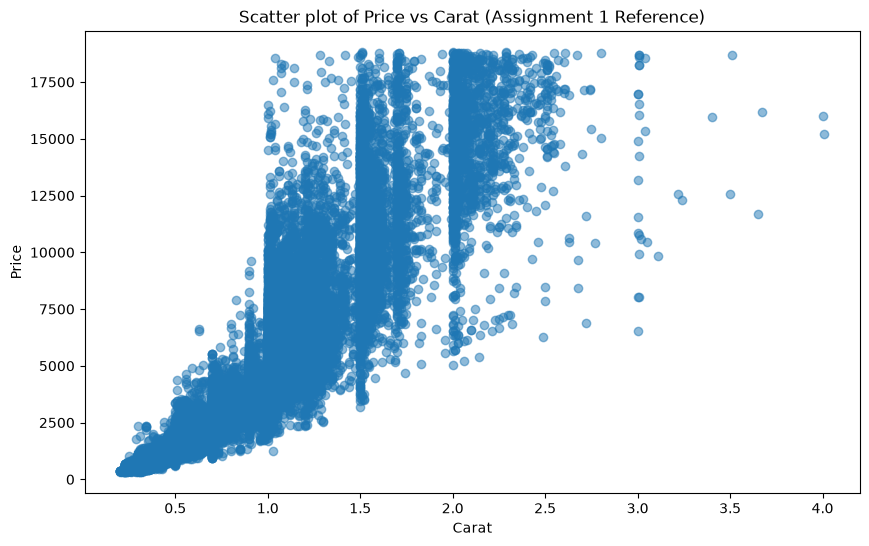

In [65]:
#To see and understand the following question: With the findings from Part 4(a), what can be further gleaned from the data after further
#model development? Refer to Parts 3(a) and 3(b) of Assignment 1. I will try to see the numbers from it
print(f"Linear Regression OrdinalEncoded RMSE: {avg_rmse:.2f}")
print(f"Linear Regression OneHotEncoded RMSE: {avg_rmse_ohe:.2f}")
print(f"Best model RMSE: {summary_df['MEAN RMSE'].min():.2f}")
print(f"Improvement in RMSE: {avg_rmse - summary_df['MEAN RMSE'].min():.2f}")
plt.figure(figsize=(10, 6))
plt.scatter(X_train[['carat']], y_train, alpha=0.5)
plt.xlabel('Carat')
plt.ylabel('Price')
plt.title('Scatter plot of Price vs Carat (Assignment 1 Reference)')
plt.show()


Documenting Findings: 
By looking at rows 8-11 (the tuned Ridge and Lasso); their RMSE values are still ~1205-1122, almost identical to the default values in rows 0-7. I am not clear if adding or changing hyperameters made them worse because they are not higher. Even with the changed hyperparameters to find the best alpha, the values of RMSE didn't make a huge impact/difference. From class we were told that these will be graph and fitted into an  'S' shape graph and maybe this means the data doesn't have to try really hard to fit. I can't speak more on fit, I am still trying to understand it and use it correctly. 

If any encoding method gave better results; by looking at the default values for all four models, the Linear OHE (1122) and Ridge OHE (1122) have lower values than their default values. This means OHE worked better and I would like to say more as to why, but the only that I udnerstood was it must of been more useful to work or use or for calculations. For decision tree the best values came from min_samples_leaf that used OrdinalEncoding compared to OHE with a score of 788.8 for min_sample_leaf.  I want to say that maybe depending on how the data is ranked does matter as taught in week 1 Ordinal took from best to worst and gave it order and it went from there to calculate and when given a tuple to use for ranking it was higher. So maybe the encoder being use does make a difference in what model its being used. 

In the scatter plot we can see the tornado going up positvely, it tells me that the carat is not the only important feature. The size: x, y, z and other features like cut, clarity and color also play a role in determining the price of a diamond. 
Best model RMSE: 620.60
Improvement in RMSE: 585.27 
These numbers demonstrate there is room for improvement, other functions of calculation could be used or changing the parameters would be recommended to try. 


Champion model to me sounds like the one with the lowest value and not the one closes to original data or what we wanted. I would say that is row 14. 
